# RAG (Zadanie 3 cz. II)

Warianty:

| wariant | kontekst |
|---|---|
| LLM (no RAG) | brak |
| LLM + RAG | jak bi + rerank, ale prompt pozwala dopowiedzieć z własnej wiedzy (oznaczone „general knowledge”) |
| RAG bi-encoder | top 5 z FAISS, odpowiedź tylko z kontekstu |
| RAG bi + rerank | top 20 z FAISS → top 5 po cross-encoderze, odpowiedź tylko z kontekstu |

## 1. CLARIN

In [1]:
from typing import cast

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from sentence_transformers import CrossEncoder, SentenceTransformer

from part1 import setup
from part1.config import resolve_backend
from part2 import config, corpus as corpus_mod, judge, llm as llm_mod, rag
from part2.retriever import PipelineRetriever, SemanticSearch

pd.set_option("display.max_colwidth", 200)
backend = resolve_backend()
print(f"backend: {backend}")

backend: cpu


In [2]:
# GET /api/v1/oapi/models
models = pd.DataFrame(llm_mod.list_models())
models[["id", "name", "type"]]

,id,name,type
0,agent-worker-example,,chat
1,dariah-eventstotriples,dariah-eventstotriples,chat
2,clarin-affect-pllum,clarin-affect-pllum,chat
3,llama3.3,llama3.3,chat
4,llama3.1-8b,llama3.1-8b,chat
5,gemma-4-31b-it,gemma-4-31b-it,chat
6,gemma-4-26b-a4b-it,gemma-4-26b-a4b-it,chat
7,deepseek-v4-flash-0731,deepseek-ai/DeepSeek-V4-Flash-0731,chat
8,pllum-fusion,pllum-fusion,chat
9,llama,llama,chat


In [3]:
MODEL_NAME = "llama3.3"             # Llama-3.3-70B-Instruct
JUDGE_MODEL = config.JUDGE_MODEL    # gemma-4-31b-it

chat = llm_mod.get_chat_model(MODEL_NAME)
judge_llm = llm_mod.get_chat_model(JUDGE_MODEL, max_tokens=100)

print(chat.invoke("Say hello in Polish, one word.").content)

Cześć


## 2. Korpus

Zbior IMDB nie ma tytułów filmów ani ich metadanych poza etykietą sentymentu, więc pytania dotyczą treści recenzji (gatunki, motywy, aktorzy wymienieni w tekście).

Dla recenzji dluzszej niz 512 tokenów chunking po słowach (z overlapem).

In [4]:
reviews = corpus_mod.load_reviews()
corpus = corpus_mod.build_corpus(reviews)

n_words = pd.Series([len(r.split()) for r in corpus.reviews])
print(f"recenzje: {len(corpus.reviews)} -> chunki: {len(corpus)}")
print(f"etykiety: {pd.Series(reviews['label']).map(corpus_mod.LABELS).value_counts().to_dict()}")
n_words.describe().round(1)

recenzje: 5000 -> chunki: 8547
etykiety: {'positive': 2506, 'negative': 2494}


count    5000.0
mean      229.6
std       168.6
min        12.0
25%       126.0
50%       173.0
75%       279.0
max      1577.0
dtype: float64


Cały dataset: train / test po 25k recenzji. Do RAG bierzemy losowe 5k z train

In [5]:
from datasets import load_dataset

load_dataset(config.DATASET_ID)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [6]:
print(reviews.features)

df = reviews.to_pandas()
df["label_name"] = df["label"].map(corpus_mod.LABELS)
df["n_words"] = df["text"].str.split().str.len()
df["n_chunks"] = pd.Series(corpus.review_ids).value_counts().sort_index().values
df.head()

{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}


,text,label,label_name,n_words,n_chunks
0,"There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simpl...",1,positive,125,1
1,"This movie is a great. The plot is very true to the book which is a classic written by Mark Twain. The movie starts of with a scene where Hank sings a song with a bunch of kids called ""when you st...",1,positive,131,1
2,"George P. Cosmatos' ""Rambo: First Blood Part II"" is pure wish-fulfillment. The United States clearly didn't win the war in Vietnam. They caused damage to this country beyond the imaginable and thi...",0,negative,177,1
3,In the process of trying to establish the audiences' empathy with Jake Roedel (Tobey Maguire) the filmmakers slander the North and the Jayhawkers. Missouri never withdrew from the Union and the Un...,1,positive,119,1
4,"Yeh, I know -- you're quivering with excitement. Well, *The Secret Lives of Dentists* will not upset your expectations: it's solidly made but essentially unimaginative, truthful but dull. It conce...",0,negative,636,4


In [7]:
# Przykłady z surowym tekstem przed czyszczeniem.

for label in ("positive", "negative"):
    row = df[df["label_name"] == label].iloc[0]
    print(f"--- {label}, {row.n_words} słów ---\n{row.text[:700]}...\n")

print(f"recenzje z <br />: {df['text'].str.contains('<br').mean():.1%}")

--- positive, 125 słów ---
There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compare, to judge, to evaluate. How about just enjoying? Funny thing too, people writing Fortier looks American but, on the other hand, arguing they prefer American series (!!!). Maybe it's the language, or the spirit, but I think this series is more English than American. By the way, the actors are real...

--- negative, 177 słów ---
George P. Cosmatos' "Rambo: First Blood Part II" is pure wish-fulfillment. The United States clearly didn't win the war in Vietnam. They caused damage to this country beyond the imaginable and this movie continues the fairy story of the oh-s

In [8]:
df.groupby("label_name")["n_words"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
negative,2494.0,228.0,161.5,15.0,128.0,174.0,278.8,1005.0
positive,2506.0,235.6,178.4,12.0,125.0,174.0,287.0,1601.0


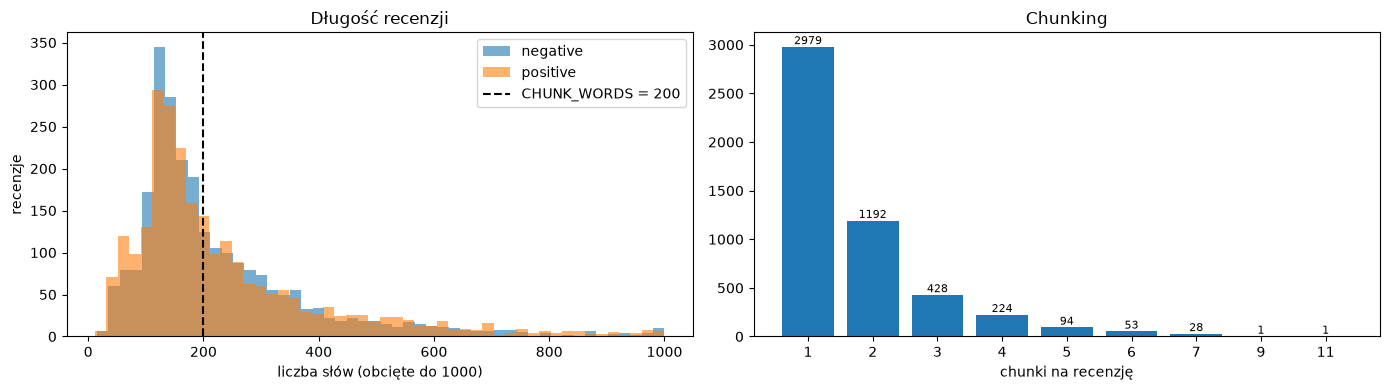

recenzje > 200 słów (więcej niż 1 chunk): 40.4%


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

for label, g in df.groupby("label_name"):
    ax1.hist(g["n_words"].clip(upper=1000), bins=50, alpha=0.6, label=label)
ax1.axvline(config.CHUNK_WORDS, ls="--", c="k", label=f"CHUNK_WORDS = {config.CHUNK_WORDS}")
ax1.set_xlabel("liczba słów (obcięte do 1000)")
ax1.set_ylabel("recenzje")
ax1.set_title("Długość recenzji")
ax1.legend()

counts = df["n_chunks"].value_counts().sort_index()
ax2.bar(counts.index.astype(str), counts.values)
ax2.set_xlabel("chunki na recenzję")
ax2.set_title("Chunking")
for x, y in zip(counts.index.astype(str), counts.values):
    ax2.text(x, y, str(y), ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

print(f"recenzje > {config.CHUNK_WORDS} słów (więcej niż 1 chunk): {(df['n_chunks'] > 1).mean():.1%}")

In [10]:
#przykład chunkingu: ostatnie CHUNK_OVERLAP słów chunka k = pierwsze słowa chunka k+1
rid = int(df.index[df["n_chunks"] == 3][0])
ids = [i for i, r in enumerate(corpus.review_ids) if r == rid]

chunks = [corpus.texts[i].split() for i in ids]
for k, words in enumerate(chunks):
    print(f"[chunk {k}] {len(words)} słów: {' '.join(words[:10])} ...")

for k in range(len(chunks) - 1):
    tail, head = chunks[k][-config.CHUNK_OVERLAP:], chunks[k + 1][:config.CHUNK_OVERLAP]
    print(f"\noverlap chunk {k} -> {k + 1}: {tail == head}")
    print(f"   koniec chunka {k}:   ... {' '.join(tail[:10])} ...")
    print(f"   początek chunka {k + 1}: {' '.join(head[:10])} ...")

[chunk 0] 200 słów: Back in the days before the Toxic Avenger, the low-camp ...
[chunk 1] 200 słów: kids deal with relationships, infidelity, unwanted pregnancies, lecherous priests, and ...
[chunk 2] 55 słów: about this movie is the killer's fixation on women - ...

overlap chunk 0 -> 1: True
   koniec chunka 0:   ... kids deal with relationships, infidelity, unwanted pregnancies, lecherous priests, and ...
   początek chunka 1: kids deal with relationships, infidelity, unwanted pregnancies, lecherous priests, and ...

overlap chunk 1 -> 2: True
   koniec chunka 1:   ... about this movie is the killer's fixation on women - ...
   początek chunka 2: about this movie is the killer's fixation on women - ...


In [11]:
bi_encoder = cast(SentenceTransformer, setup.get_model(config.BI_ENCODER_MODEL_ID, device=backend))
cross_encoder = cast(CrossEncoder, setup.get_model(config.CROSS_ENCODER_MODEL_ID, device=backend))

embeddings = corpus_mod.corpus_embeddings(bi_encoder, corpus, device=backend)
print(f"osadzenia: {tuple(embeddings.shape)}")

search = SemanticSearch(bi_encoder, corpus, embeddings, cross_encoder=cross_encoder, device=backend)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

osadzenia: (8547, 768)


## 3. Retrieval

In [12]:
MODES = {
    "bi-encoder": dict(use_reranker=False),
    "bi + rerank": dict(use_reranker=True),
}

def show_hits(query: str) -> None:
    for tag, kwargs in MODES.items():
        print(f"\n=== {tag}: {query}")
        for rank, h in enumerate(search.search(query, **kwargs), start=1):
            ce = f" ce={h.ce_score:.2f}" if h.ce_score is not None else "" # ce = scpre cross-encodera, logit bez sigmoidy
            print(f"{rank}. [review {h.review_id}/{h.chunk_id}, {h.label}, bi_rank={h.bi_rank}, bi={h.bi_score:.2f}{ce}]") #bi_rank - pozycja po biencoderze
            print(f"   {h.text[:200]}...")

show_hits("Which horror movies have a disappointing ending?")


=== bi-encoder: Which horror movies have a disappointing ending?


1. [review 3492/3, positive, bi_rank=1, bi=23.89]
   on display on the sculptures. A dream sequence provides a great moment of suspense, but what ultimately kills this one is the slow pace. It takes a long time for events to unfold out, and most of the ...
2. [review 138/0, positive, bi_rank=2, bi=23.82]
   John Carpenter's Halloween is quite frankly a horror masterpiece. It tells the immortal story of escaped mental patient Michael Myers, who returns to his hometown on Halloween night to stalk and kill ...
3. [review 4192/1, negative, bi_rank=3, bi=23.60]
   the only truly grisly imagery comes right at the end when the bodies of the victims are discovered by the remaining survivor (there is one notably bloody dismembered corpsethe film could've done with...
4. [review 526/0, positive, bi_rank=4, bi=23.25]
   MINOR SPOILER Underrated little Stephen King shocker. It's not perfect, by any stretch of the imagination--even if the limp performances of Dale Midkiff and Denise Crosby were be

* bi-encoder daje na 2. miejscu recenzję chwalącą Halloween - dopasował "horror", a nie "rozczarowujące zakończenie"
* reranker wyciąga na 1. miejsce recenzję, którą bi-encoder miał na 10. pozycji
* 3 z 5 chunków po rerankingu ma ce < 0, czyli słabe dopasowanie mimo top 5

## 4. RAG


In [13]:
print(rag.RAG_PROMPT.format(context="[1] (review #0, sentiment: positive)\n<chunk>", question="<pytanie>"))
print("\n--- LLM + RAG ---\n" + rag.HYBRID_SYSTEM_PROMPT)

System: You are an assistant that answers questions about movies using ONLY the movie review excerpts provided in the context.

Rules:
1. Base the answer strictly on the context. Do not use outside knowledge about films, actors or plots.
2. Cite the excerpts you used with their numbers in square brackets, e.g. [1], [3].
3. If the context does not contain the information needed, say clearly that the reviews do not answer the question - do not guess.
4. Reviews are subjective opinions: report them as opinions ("one reviewer thinks...") and mention when reviewers disagree.
5. Be concise (at most 5 sentences). Answer in the same language as the question.
Human: Context (movie review excerpts):
[1] (review #0, sentiment: positive)
<chunk>

Question: <pytanie>

Answer:

--- LLM + RAG ---
You are an assistant that answers questions about movies. You are given movie review excerpts as context.

Rules:
1. Use the excerpts first and cite them with their numbers in square brackets, e.g. [1], [3].

In [14]:
retriever_bi = PipelineRetriever(search_engine=search, use_reranker=False)
retriever_ce = PipelineRetriever(search_engine=search, use_reranker=True)

chains = {
    "LLM (no RAG)": rag.build_no_rag_chain(chat),
    "LLM + RAG": rag.build_rag_chain(retriever_ce, chat, prompt=rag.HYBRID_PROMPT),
    "RAG bi-encoder": rag.build_rag_chain(retriever_bi, chat),
    "RAG bi + rerank": rag.build_rag_chain(retriever_ce, chat),
}
VARIANTS = list(chains)

## 5. Zapytania

In [15]:
QUERIES = {
    "What do reviewers criticize about the endings of horror movies?": "opinia",
    "What do people like about Disney animated films?": "opinia",
    "Which war movies are described as realistic?": "opinia",
    "Why do some viewers think remakes are worse than the originals?": "opinia",
    "What do reviewers say about bad special effects in low-budget sci-fi films?": "opinia",
    "Which movies are recommended for children and why?": "opinia",
    "Do reviewers think that musicals are boring?": "opinia",
    "Is there a review praising the acting of Meryl Streep? What does it say?": "fakt w korpusie",
    "What do reviewers say about Fred Gwynne's performance?": "fakt w korpusie",
    "What is the box office revenue of Avatar 2?": "poza korpusem",
    "Why do reviewers say that Titanic is a comedy?": "fałszywe założenie",
    "Which movies do reviewers describe as not boring at all?": "negacja",
    "Co recenzenci myślą o filmach o zombie?": "PL, wspólne słowo",
    "Jakie filmy o wojnie recenzenci uważają za wiarygodne i bliskie prawdy?": "PL, bez wspólnych słów",
}

results = pd.DataFrame(rag.run_variants(QUERIES, chains))
results["type"] = results["query"].map(QUERIES)
results[["type", "query", "variant", "seconds", "error"]]

,type,query,variant,seconds,error
0,opinia,What do reviewers criticize about the endings of horror movies?,LLM (no RAG),2.75,None
1,opinia,What do reviewers criticize about the endings of horror movies?,LLM + RAG,5.26,None
2,opinia,What do reviewers criticize about the endings of horror movies?,RAG bi-encoder,2.68,None
3,opinia,What do reviewers criticize about the endings of horror movies?,RAG bi + rerank,4.89,None
4,opinia,What do people like about Disney animated films?,LLM (no RAG),1.78,None
5,opinia,What do people like about Disney animated films?,LLM + RAG,4.80,None
6,opinia,What do people like about Disney animated films?,RAG bi-encoder,2.35,None
7,opinia,What do people like about Disney animated films?,RAG bi + rerank,4.80,None
8,opinia,Which war movies are described as realistic?,LLM (no RAG),1.77,None
9,opinia,Which war movies are described as realistic?,LLM + RAG,4.26,None


In [16]:
def show_query(query: str) -> None:
    display(Markdown(f"### {query} *({QUERIES[query]})*"))
    for _, r in results[results["query"] == query].iterrows():
        src = ", ".join(f"#{s} ({l})" for s, l in zip(r["sources"], r["source_labels"])) or "-"
        display(Markdown(f"**{r['variant']}** ({r['seconds']} s) - źródła: {src}\n\n{r['answer'] or r['error']}"))

In [17]:
show_query("What do reviewers criticize about the endings of horror movies?")

### What do reviewers criticize about the endings of horror movies? *(opinia)*

**LLM (no RAG)** (2.75 s) - źródła: -

Reviewers often criticize horror movie endings for being implausible, convenient, or overly reliant on plot twists. Some endings are also panned for being too abrupt or rushed, leaving unanswered questions or unresolved plot threads. Additionally, critics may feel that a horror movie's ending undermines the tension and suspense built up throughout the film. Others may criticize endings that rely on clichés, such as the "final girl" trope or the villain's unexplained survival. Overall, a poorly executed ending can detract from the overall impact and effectiveness of a horror movie.

**LLM + RAG** (5.26 s) - źródła: #843 (negative), #1060 (negative), #526 (positive), #4501 (positive), #3488 (negative)

Reviewers criticize the endings of horror movies for being contrived, stupid, and tacked on [1] [2]. One reviewer thinks that the ending of a particular movie is "hokey" [3]. Another reviewer mentions that the ending is not satisfying and makes the movie feel like a waste of time [1]. Overall, reviewers seem to dislike endings that feel forced or unoriginal. (general knowledge) This is a common criticism of horror movies, as a poorly executed ending can ruin the entire film.

**RAG bi-encoder** (2.68 s) - źródła: #843 (negative), #4739 (negative), #4422 (negative), #4192 (negative), #3766 (negative)

Reviewers criticize the endings of horror movies for being predictable [1], contrived [1], and lacking a good scare [1]. One reviewer mentions that the ending of a movie was "nice unexpectedly downbeat" but still not enough to save the film from its overall poor quality [4]. Another reviewer criticizes the "surprise" ending of a movie as requiring "tremendous endurance" to reach [1]. Overall, the reviewers think that the endings of these horror movies are unimpressive and unsatisfying. [1, 4]

**RAG bi + rerank** (4.89 s) - źródła: #843 (negative), #1060 (negative), #526 (positive), #4501 (positive), #3488 (negative)

Reviewers criticize the endings of horror movies for being contrived, stupid, and tacked on [1, 2]. One reviewer thinks the ending is hokey [3], while another mentions a "surprise" ending that requires tremendous endurance to reach [1]. The critics seem to agree that poorly executed endings can significantly detract from the overall experience of a horror movie.

* bez RAG same ogólniki o horrorach, bez żadnego źródła
* bi-encoder i rerank mają tylko 1 wspólny chunk - rerank wyciąga recenzję o "contrived twist ending", którą bi-encoder miał na 16. miejscu
* LLM + RAG to prawie ta sama odpowiedź co rerank + oznaczony ogólnik na końcu

In [18]:
show_query("What do people like about Disney animated films?")

### What do people like about Disney animated films? *(opinia)*

**LLM (no RAG)** (1.78 s) - źródła: -

People like Disney animated films for their memorable characters, catchy music, and timeless stories. The films often feature lovable protagonists, humorous sidekicks, and iconic villains, making them appealing to audiences of all ages. The movies also typically convey valuable life lessons and moral values, such as friendship, perseverance, and self-discovery. Additionally, the vibrant animation and attention to detail bring the stories to life, creating a magical and immersive experience. Overall, Disney's unique blend of storytelling, music, and animation has made their films beloved by generations of fans.

**LLM + RAG** (4.8 s) - źródła: #4721 (positive), #305 (positive), #2395 (positive), #4986 (positive), #1439 (positive)

One reviewer thinks that Disney's traditional form of animation is still enjoyable and has a place in the market, even with the rise of CG movies [2]. Another reviewer praises the "magic and enchantment" that old Disney is known for, which is still present in their simpler works [3]. Reviewers also appreciate the unique visual styles, such as the backgrounds and characters, in Disney animated films [1, 5]. The music and lack of singing in some films are also seen as positives [1]. Additionally, the humor and likable characters, like Jaques the mouse, are enjoyed by viewers [3].

**RAG bi-encoder** (2.35 s) - źródła: #4561 (positive), #4986 (positive), #4703 (positive), #305 (positive), #2395 (positive)

One reviewer thinks that Disney animated films are great because they offer a mix of action, adventure, intrigue, and imagination without the need for songs [1]. Another reviewer enjoys the beautifully illustrated scenery and non-stop excitement [1]. Some also appreciate the lovable and identifiable characters [1], as well as the humour and satire that cartoons can provide [3]. Additionally, reviewers like the clever jokes that suit all ages [4] and the magic and enchantment that old Disney films are known for [5]. Overall, people seem to enjoy the unique blend of storytelling, animation, and characters that Disney animated films offer.

**RAG bi + rerank** (4.8 s) - źródła: #4721 (positive), #305 (positive), #2395 (positive), #4986 (positive), #1439 (positive)

One reviewer thinks that Disney animated films have a certain "magic and enchantment" that makes them special [3]. Others appreciate the unique visual style, beautiful scenery, and backgrounds in these films [1, 5]. The cleverness, humor, and ability to appeal to all ages are also mentioned as positives [2, 4]. Additionally, some reviewers enjoy the lovable and humorous characters in Disney animated films [3, 5]. Overall, reviewers seem to enjoy the imaginative and entertaining aspects of Disney animated films.

* bez RAG typowy opis Disneya (muzyka, morały) - brzmi dobrze, ale nie pochodzi z recenzji
* wszystkie warianty RAG mają 5/5 pozytywnych źródeł i podobne odpowiedzi

In [19]:
show_query("Which war movies are described as realistic?")

### Which war movies are described as realistic? *(opinia)*

**LLM (no RAG)** (1.77 s) - źródła: -

Some war movies described as realistic include "Saving Private Ryan" (1998), "Platoon" (1986), and "Black Hawk Down" (2001). These films are known for their intense and graphic portrayals of war. "Lone Survivor" (2013) and "American Sniper" (2014) are also considered realistic depictions of war. These movies often consult with veterans and use realistic special effects to create an immersive experience. They aim to accurately convey the chaos and brutality of war.

**LLM + RAG** (4.26 s) - źródła: #98 (positive), #2465 (positive), #4487 (positive), #4589 (positive), #2557 (negative)

One reviewer thinks that "Pride Of The Marines" is a realistic war film, as it portrays a true story in a reasonably accurate manner [1]. Another reviewer praises the realism of the battle scene in the same film, but notes that the lack of visible bullet impacts hurts the realism [2]. (general knowledge) Other war movies are not mentioned as being realistic in the provided excerpts.

**RAG bi-encoder** (1.87 s) - źródła: #98 (positive), #4487 (positive), #3029 (negative), #4589 (positive), #4487 (positive)

One reviewer thinks that "Pride Of The Marines" is a realistic war movie, as it portrays a true story in a reasonably accurate manner [1]. In contrast, the reviewer criticizes US war films made during WWII, such as "Air Force", for lacking realism [1]. The other reviews do not specifically describe the movies as realistic, but rather focus on their portrayal of war and its effects [2], [3], [4], [5].

**RAG bi + rerank** (4.26 s) - źródła: #98 (positive), #2465 (positive), #4487 (positive), #4589 (positive), #2557 (negative)

One reviewer thinks that "Pride Of The Marines" is a realistic war film, as it portrays a true story in a reasonably accurate manner [1]. Another reviewer notes that "Pride Of The Marines" is a welcome departure from other war films that lack realism [1]. However, a reviewer of a different film, notes that the battle scene in the film they are reviewing is superb, but criticizes the lack of realism in the depiction of bullet impacts [2]. The reviews do not provide information on the realism of the other films mentioned.

* bez RAG znane tytuły (Saving Private Ryan, Platoon, Black Hawk Down), których nie ma w recenzjach
* RAG znajduje film z korpusu (Pride of the Marines)
* LLM + RAG oznacza jako general knowledge zdanie o tym, czego nie ma w kontekście - etykieta źle użyta

In [20]:
show_query("Why do some viewers think remakes are worse than the originals?")

### Why do some viewers think remakes are worse than the originals? *(opinia)*

**LLM (no RAG)** (1.99 s) - źródła: -

Some viewers think remakes are worse than the originals because they often feel that the remake lacks the originality and charm of the first film. Additionally, remakes can be seen as unnecessary or motivated by profit rather than a desire to tell a new story. Viewers may also feel a strong emotional attachment to the original, making it difficult for the remake to live up to their expectations. This phenomenon is often referred to as "nostalgia bias." Overall, the perception that remakes are inferior is often subjective and influenced by personal taste and nostalgia.

**LLM + RAG** (5.95 s) - źródła: #486 (negative), #1262 (negative), #1059 (negative), #4099 (negative), #3480 (negative)

One reviewer thinks remakes are often made to "steal someone's idea and reshaping it" for a modern audience, rather than creating something original [4]. Another reviewer believes that remakes can lack the charm and quality of the original, citing the example of "The Blob" where the remake is considered better than the original, but in other cases, such as "Double Indemnity", the remake is inferior [1] [2]. Some viewers also feel that remakes can be motivated by a desire to cash in on the success of the original, rather than a genuine attempt to create something new or improve upon the original (general knowledge). Reviewers disagree on the quality of remakes, with some enjoying them, such as the remake of "Invasion of the Body Snatchers", while others dislike them, like the remake of "The Wicker Man" [3]. Overall, the opinion on remakes varies, with some seeing them as unnecessary or inferior, while others appreciate them as a new interpretation of a classic story.

**RAG bi-encoder** (2.44 s) - źródła: #4099 (negative), #4099 (negative), #3246 (negative), #1059 (negative), #486 (negative)

One reviewer thinks remakes are worse because they often "dump everything in a blender, purify all that is more puzzling and curious and throw in a few artificial flavors" [1], resulting in a loss of character, atmosphere, and story [2]. Another reviewer believes that remakes can be bad due to "cheesy special effects, dumb stereotypes, crummy action scenes and bad, bad acting" [3]. Additionally, some viewers feel that remakes can solidify negative tendencies, such as sexism and misogyny, in the filmmakers [4]. However, it's worth noting that not all reviewers think remakes are inherently worse, with one reviewer preferring the remake of "The Blob" to the original [5].

**RAG bi + rerank** (5.84 s) - źródła: #486 (negative), #1262 (negative), #1059 (negative), #4099 (negative), #3480 (negative)

One reviewer thinks remakes are often made to "steal someone's idea and reshaping it" for a modern audience, rather than being a genuine tribute to the original [4]. Another reviewer believes that remakes can be inferior due to changes in setting, taste, and style, citing the 1973 TV remake of a classic as an example [2]. Additionally, some reviewers feel that remakes lack the quality and charm of the originals, with one stating that the remake of "The Wicker Man" solidified their opinion of the writer/director's sexism and misogynistic tendencies [3]. Overall, the reviewers seem to think that remakes are often motivated by commercial rather than artistic reasons, leading to a decrease in quality. [1] also mentions that the original "The Blob" is considered a classic, but the reviewer thinks the remake is better, showing that opinions on remakes can vary.

* wszystkie źródła negatywne, odpowiedzi potwierdzają tezę z pytania
* bi-encoder ma ten sam chunk dwa razy i cytuje go jako [1] i [2]

In [21]:
show_query("What do reviewers say about bad special effects in low-budget sci-fi films?")

### What do reviewers say about bad special effects in low-budget sci-fi films? *(opinia)*

**LLM (no RAG)** (2.24 s) - źródła: -

Reviewers often criticize low-budget sci-fi films for having subpar special effects, stating that they can be distracting and take away from the overall viewing experience. Some reviewers note that poor special effects can make a film look cheesy or amateurish. However, others argue that low-budget films can still be enjoyable despite lacking polished special effects, as long as the story and characters are well-developed. A few reviewers even praise low-budget films for their creative use of limited resources to achieve impressive effects. Overall, the consensus is that while good special effects can enhance a film, they are not the only factor in determining a movie's quality.

**LLM + RAG** (5.54 s) - źródła: #4012 (negative), #2598 (positive), #1166 (negative), #1494 (negative), #1599 (negative)

One reviewer thinks that bad special effects can be a major part of the comedy in a sci-fi film, but was disappointed that "Sands of Oblivion" lacked this [3]. Another reviewer criticizes the special effects in a 2005 film, stating that they look "low budget" and resemble those from older films like "The Birds" [1]. In contrast, a positive review of a different film notes that although the CGI "isn't great", it doesn't detract from the film [2]. Reviewers disagree on the impact of bad special effects, with some finding them charming or comedic and others seeing them as a flaw. (general knowledge) Low-budget films often face challenges in producing high-quality special effects.

**RAG bi-encoder** (2.68 s) - źródła: #1526 (positive), #595 (negative), #4012 (negative), #1166 (negative), #4847 (negative)

Reviewers think that bad special effects can be a major issue in low-budget sci-fi films. One reviewer [3] states that the special effects were so bad that it was "a disservice to the field of special effects" and looked "low budget". Another reviewer [1] mentions that the special effects are "never quite integrated into the rest very well", although they still enjoyed the film overall. Reviewer [4] notes that the minimal CGI special effects were a disappointment, as they are often a source of comedy in sci-fi films. However, reviewer [3] also suggests that the film's bad special effects can be entertaining in a "so-bad-it's-good" way.

**RAG bi + rerank** (5.2 s) - źródła: #4012 (negative), #2598 (positive), #1166 (negative), #1494 (negative), #1599 (negative)

One reviewer thinks that bad special effects can be a major source of comedy in a sci-fi film, but was disappointed that "Sands of Oblivion" lacked this [3]. Another reviewer criticizes the special effects in a 2005 film, stating that they look "low budget" and "cheesy" [1]. However, a different reviewer notes that while the CGI in a low-budget film isn't great, it doesn't detract from the film [2]. Overall, reviewers have mixed opinions on the impact of bad special effects in low-budget sci-fi films.

* bi-encoder i rerank mają 2 wspólne chunki, więc odpowiedzi opierają się na innych recenzjach, ale wnioski wychodzą podobne

In [22]:
show_query("Which movies are recommended for children and why?")

### Which movies are recommended for children and why? *(opinia)*

**LLM (no RAG)** (1.82 s) - źródła: -

Some highly recommended movies for children include "Inside Out", "The Lion King", and "Finding Nemo". These films are chosen for their engaging storylines, lovable characters, and valuable life lessons. They promote emotional intelligence, friendship, and perseverance, making them suitable for young audiences. Additionally, movies like "The Jungle Book" and "Toy Story" are also popular among kids for their entertaining and imaginative content. These films are generally rated G or PG, ensuring they are appropriate for children.

**LLM + RAG** (5.31 s) - źródła: #4244 (positive), #909 (negative), #3295 (positive), #909 (negative), #4878 (positive)

One reviewer thinks that "Faerie Tale Theatre" is great for little kids because it's a classic Cinderella story [1]. Another reviewer recommends "Ice Age, Monsters Inc., the Incredibles, Shrek, A Bug's Life" as better options for children than the movie they were reviewing [2]. A positive review of "Paulie" suggests it's suitable for both adults and children to watch together, with elements of laughter, tears, love, and adventure [3]. In contrast, some reviewers strongly advise against certain movies, citing dark and scary elements, violence, and crudeness [2, 4]. A reviewer also recommends a film for its beauty and ability to introduce young people to the wonder of nature, making it a relaxing view for all ages [5].

**RAG bi-encoder** (1.99 s) - źródła: #985 (positive), #985 (positive), #3295 (positive), #909 (negative), #909 (negative)

One reviewer thinks "How to Eat Fried Worms" is a good movie for kids, as it is a "feel good fun film" that portrays true friendship and acceptance [1, 2]. Another reviewer recommends "Paulie" as a movie that adults and children can watch together, citing its laughter, tears, love, and adventure [3]. In contrast, a negative review suggests renting "Ice Age", "Monsters Inc.", "The Incredibles", "Shrek", or "A Bug's Life" instead of the movie being reviewed, implying that these are better options for children [4, 5].

**RAG bi + rerank** (5.12 s) - źródła: #4244 (positive), #909 (negative), #3295 (positive), #909 (negative), #4878 (positive)

One reviewer thinks that "Faerie Tale Theatre" is great for little kids because it's a classic Cinderella story [1]. Another reviewer recommends "Ice Age, Monsters Inc., the Incredibles, Shrek, A Bug's Life" as better options for children than the movie they are reviewing [2]. A reviewer also suggests that the movie they are reviewing, about a parrot named Paulie, is suitable for children and adults to watch together [3]. In contrast, some reviewers strongly advise against certain movies for children due to their dark and scary elements [2, 4]. A reviewer also recommends a film about a girl and a fox, saying it introduces young people to the beauty and wonder of nature [5].

* bez RAG znane tytuły (The Lion King, Finding Nemo)
* bi-encoder ma tylko 3 różne recenzje na 5 miejsc
* rerank i LLM + RAG piszą "some reviewers strongly advise against... [2, 4]", a to ta sama recenzja (kontekst w sekcji 6.2)

In [23]:
show_query("Do reviewers think that musicals are boring?")

### Do reviewers think that musicals are boring? *(opinia)*

**LLM (no RAG)** (1.52 s) - źródła: -

Not necessarily, as opinions on musicals vary among reviewers. Some critics praise musicals for their energetic performances, catchy soundtracks, and creative storytelling. However, others may find certain musicals to be overly cheesy, predictable, or lacking in substance. Ultimately, reviews of musicals depend on the specific film and the reviewer's personal taste. I don't have a general consensus on whether reviewers think musicals are boring overall.

**LLM + RAG** (4.74 s) - źródła: #1193 (positive), #4539 (negative), #373 (negative), #504 (positive), #2179 (negative)

One reviewer thinks that musicals can be boring, specifically mentioning that "The Tunnel of Love" (not explicitly mentioned but presumably referred to as "TTONO") is "almost all singing and dancing" which can be boring if you're not into it [1]. Another reviewer also expresses a similar sentiment, stating that musicals are "stranger than any science-fiction film" and that the sudden singing and dancing can be jarring [2]. However, not all reviewers share this opinion, as one reviewer enjoys musicals like "Guys and Dolls" for their entertainment value [4].

**RAG bi-encoder** (2.24 s) - źródła: #4789 (negative), #1845 (negative), #4937 (negative), #2179 (negative), #1193 (positive)

Not all reviewers think that musicals are boring, but some do. One reviewer thinks that a particular musical is boring due to excessive singing and dancing [5]. Another reviewer criticizes the presentation of musical numbers, making the film feel lethargic [2]. However, the boredom seems to be specific to certain films, rather than a general opinion about musicals as a genre. Reviewers also criticize specific aspects such as poor music, bad editing, and miscasting [1], [4].

**RAG bi + rerank** (4.62 s) - źródła: #1193 (positive), #4539 (negative), #373 (negative), #504 (positive), #2179 (negative)

One reviewer thinks that musicals can be boring, specifically mentioning that the film in question has "so much dancing and dancing and dancing" which can be boring if you're not into it [1]. Another reviewer mentions that musicals are "stranger than any science-fiction film" and that they don't "get" musicals, implying that they may find them boring or unengaging [2]. However, not all reviewers share this opinion, as one reviewer enjoys musicals and finds them entertaining, citing "Guys and Dolls" as a favorite [4].

* LLM + RAG zgaduje tytuł filmu ("The Tunnel of Love... presumably TTONO") i nie oznacza tego jako general knowledge

In [24]:
show_query("Is there a review praising the acting of Meryl Streep? What does it say?")

### Is there a review praising the acting of Meryl Streep? What does it say? *(fakt w korpusie)*

**LLM (no RAG)** (1.9 s) - źródła: -

Yes, there are many reviews praising Meryl Streep's acting. One review from The New York Times states that she is "an actress of unparalleled range and depth". The review highlights her ability to fully inhabit her characters, bringing nuance and complexity to her performances. It praises her "remarkable talent" and "profound emotional intelligence" on screen. The review concludes that she is "one of the greatest actresses of our time".

**LLM + RAG** (4.25 s) - źródła: #1721 (positive), #3571 (negative), #4345 (positive), #3982 (positive), #3857 (positive)

One reviewer thinks Meryl Streep's performance is excellent [1]. According to this review, she "brings me to go into the heart of her role" [1]. Another reviewer also mentions Meryl Streep as part of an ensemble cast with "brief but very solid performances" [3]. However, not all reviewers share this opinion, as one reviewer states they do not like films with Meryl Streep [2].

**RAG bi-encoder** (1.7 s) - źródła: #1721 (positive), #2608 (positive), #4345 (positive), #3982 (positive), #1081 (positive)

One reviewer thinks Meryl Streep's performance is excellent [1]. According to this review, she "brings me to go into the heart of her role" and is "most impressive" [1]. Another review also mentions Meryl Streep as part of an ensemble cast with "brief but very solid performances" [3].

**RAG bi + rerank** (4.53 s) - źródła: #1721 (positive), #3571 (negative), #4345 (positive), #3982 (positive), #3857 (positive)

One reviewer thinks Meryl Streep's performance is excellent [1]. According to this review, she "brings me to go into the heart of her role" and is "most impressive" [1]. Another reviewer also mentions Meryl Streep as part of an ensemble cast with "brief but very solid performances" [3]. However, not all reviewers share this opinion, as one reviewer states they do not like films with Meryl Streep [2].

* bez RAG model zmyśla recenzję z New York Times razem z cytatami
* RAG cytuje prawdziwą recenzję z korpusu
* rerank dokłada głos przeciwny (recenzent, który nie lubi filmów z nią)

In [25]:
show_query("What do reviewers say about Fred Gwynne's performance?")

### What do reviewers say about Fred Gwynne's performance? *(fakt w korpusie)*

**LLM (no RAG)** (2.05 s) - źródła: -

Reviewers praise Fred Gwynne's performance, particularly his portrayal of Herman Munster in the TV series "The Munsters". They note his ability to bring a lovable and comedic touch to the character. His performance is often described as iconic and memorable. Gwynne's talent for physical comedy and his chemistry with co-stars are also frequently highlighted. Overall, his performance is widely regarded as a key factor in the show's enduring popularity.

**LLM + RAG** (4.34 s) - źródła: #473 (negative), #2458 (negative), #4842 (negative), #3336 (positive), #3311 (positive)

There is no mention of Fred Gwynne's performance in the provided excerpts [1]-[5]. (general knowledge) Fred Gwynne was an American actor, but without more information, it's impossible to determine what reviewers thought of his performance in a specific movie.

**RAG bi-encoder** (1.52 s) - źródła: #2463 (positive), #1426 (positive), #3336 (positive), #569 (positive), #770 (positive)

The reviews do not answer the question, as there is no mention of Fred Gwynne's performance in the provided excerpts [1], [2], [3], [4], [5].

**RAG bi + rerank** (4.18 s) - źródła: #473 (negative), #2458 (negative), #4842 (negative), #3336 (positive), #3311 (positive)

The reviews do not answer the question, as there is no mention of Fred Gwynne's performance in the provided excerpts.

* nazwisko jest w 4 recenzjach, ale żaden wariant ich nie znalazł
   * bi-encoder słabo dopasowuje rzadkie nazwy własne - to jedno zdanie w długiej recenzji, a embedding chunka niesie sens całości
   * pomógłby hybrydowy retrieval (BM25 + dense)
* bez RAG odpowiedź o The Munsters - z wiedzy ogólnej, nie z recenzji
* LLM + RAG nawet tego nie dopowiada, tylko ogólnik "was an American actor"

In [26]:
show_query("What is the box office revenue of Avatar 2?")

### What is the box office revenue of Avatar 2? *(poza korpusem)*

**LLM (no RAG)** (2.12 s) - źródła: -

The box office revenue of Avatar: The Way of Water (2022) has surpassed $2.32 billion worldwide, making it one of the highest-grossing films of all time. In the United States, it has grossed over $636 million. The film's global success can be attributed to its stunning visuals and loyal fan base. As of my knowledge cutoff, these numbers are subject to change. I don't have real-time data, but these figures are the most recent available.

**LLM + RAG** (4.27 s) - źródła: #1002 (negative), #3530 (negative), #4858 (positive), #289 (negative), #611 (negative)

There is no information about Avatar 2 in the provided excerpts [1]-[5]. (general knowledge) Avatar 2 is a separate movie that is not mentioned in the given context, which seems to be discussing a different film with a disputed budget.

**RAG bi-encoder** (1.0 s) - źródła: #289 (negative), #3530 (negative), #2032 (positive), #611 (negative), #2684 (negative)

The reviews do not answer the question. There is no mention of Avatar 2 in the provided review excerpts.

**RAG bi + rerank** (4.08 s) - źródła: #1002 (negative), #3530 (negative), #4858 (positive), #289 (negative), #611 (negative)

The reviews do not answer the question. There is no mention of Avatar 2 in the provided review excerpts.

* bez RAG kwota z pamięci
* wszystkie warianty z kontekstem odmawiają, LLM + RAG też, choć mógł dopowiedzieć z własnej wiedzy

In [27]:
show_query("Why do reviewers say that Titanic is a comedy?")

### Why do reviewers say that Titanic is a comedy? *(fałszywe założenie)*

**LLM (no RAG)** (1.95 s) - źródła: -

Reviewers do not say that Titanic is a comedy. The film is actually a romantic epic disaster movie, directed by James Cameron, and is known for its tragic love story and historical drama. It's possible that you may have come across a satirical or humorous article or review that jokingly referred to Titanic as a comedy, but this is not a serious or accurate assessment of the film. Titanic is widely regarded as a dramatic and emotional film, not a comedy.

**LLM + RAG** (4.92 s) - źródła: #2730 (positive), #1204 (positive), #1750 (positive), #3352 (positive), #1402 (positive)

Reviewers do not say that Titanic is a comedy. In fact, none of the provided excerpts [1]-[4] mention Titanic being a comedy. The mention of a "light hearted, tongue in cheek, family comedy" is actually from excerpt [5], which appears to be a review of a different movie, not Titanic. One reviewer thinks that people should take films for what they are supposed to be, entertainment, and not compare them to classics like "Taxi Driver" or "The Godfather" [5]. (general knowledge) Titanic is generally known as a romantic epic disaster film, not a comedy.

**RAG bi-encoder** (1.33 s) - źródła: #3352 (positive), #3352 (positive), #2730 (positive), #1750 (positive), #1204 (positive)

The reviews do not answer the question. None of the provided excerpts mention Titanic being a comedy [1], [2], [3], [4], [5]. In fact, they all describe it as a romantic epic disaster film with a tragic love story.

**RAG bi + rerank** (4.3 s) - źródła: #2730 (positive), #1204 (positive), #1750 (positive), #3352 (positive), #1402 (positive)

The reviews do not answer the question. In fact, review [5] seems to be about a different movie, as it mentions a film that is a "light hearted, tongue in cheek, family comedy" and mentions Carey, which is not related to Titanic. The other reviews [1], [2], [3], and [4] discuss Titanic as a romantic drama or disaster film, but none of them mention it being a comedy.

* wszystkie warianty odrzucają tezę, bo model zna ten film
* rerank zauważa, że [5] jest o zupełnie innej komedii
* LLM + RAG oznacza jako general knowledge wniosek o kontekście, a nie wiedzę

In [28]:
show_query("Which movies do reviewers describe as not boring at all?")

### Which movies do reviewers describe as not boring at all? *(negacja)*

**LLM (no RAG)** (2.36 s) - źródła: -

Reviewers often describe action-packed movies like "Mad Max: Fury Road" and "The Dark Knight" as not boring at all. Other examples include thrilling films like "Inception" and "Interstellar", which keep viewers engaged with complex plots and stunning visuals. Fast-paced movies like "The Bourne Series" and "Mission: Impossible" are also frequently praised for their non-stop action and suspense. These films are known for their ability to keep audiences on the edge of their seats. Critics consistently praise these movies for their energy and ability to hold viewers' attention.

**LLM + RAG** (6.03 s) - źródła: #2277 (negative), #146 (negative), #3731 (negative), #3720 (positive), #2277 (negative)

One reviewer thinks that "The cook, the thief, his wife and her lover" [1] and "A zed and two noughts" [1] are not boring, despite having content that pushes boundaries. Another reviewer enjoys "Fever Pitch" [4] and finds it to be a "fun time" without being pretentious. (general knowledge) These movies are described as engaging and entertaining, unlike the movies that the reviewers found boring, such as the one based on Shakespeare [1] and the war film [3]. Reviewers disagree on what makes a movie boring or not, with some appreciating stylized and boundary-pushing content [1] and others finding it off-putting [1].

**RAG bi-encoder** (2.06 s) - źródła: #2277 (negative), #306 (positive), #3821 (negative), #146 (negative), #4851 (positive)

One reviewer thinks that "Stardust" is not boring at all, describing it as a "diamond in the rough" [2]. Another reviewer enjoys "I.Q." and finds it "nice and sweet" to watch, without feeling robbed or bored [5]. In contrast, other movies are described as boring by different reviewers [1], [3], [4].

**RAG bi + rerank** (4.78 s) - źródła: #2277 (negative), #146 (negative), #3731 (negative), #3720 (positive), #2277 (negative)

One reviewer thinks that "The cook, the thief, his wife and her lover" [1] and "A zed and two noughts" [1] are not boring, despite having content that pushes boundaries. Another reviewer finds "Fever Pitch" [4] to be a fun and enjoyable movie, not boring at all. In contrast, other movies are described as boring by different reviewers [1], [2], [3], [5].

* bez RAG lista hitów (Mad Max, The Dark Knight), nie z recenzji
* bi-encoder zwraca głównie recenzje o nudnych filmach - negacja jest ignorowana
* rerank i LLM + RAG wyciągają "not boring" z negatywnej recenzji - nadinterpretacja

In [29]:
show_query("Co recenzenci myślą o filmach o zombie?")

### Co recenzenci myślą o filmach o zombie? *(PL, wspólne słowo)*

**LLM (no RAG)** (5.52 s) - źródła: -

Recenzenci mają różne opinie o filmach o zombie, ale wielu z nich uważa, że są one interesującym gatunkiem, który pozwala na eksplorację tematów takich jak przetrwanie, społeczeństwo i ludzka natura. Niektórzy chwalą filmy o zombie za ich zdolność do wywoływania strachu i napięcia, podczas gdy inni krytykują je za brak oryginalności i nadmiar przemocy. Filmy takie jak "Shaun of the Dead" i "28 Days Later" są często wymieniane jako przykłady dobrych filmów o zombie, które łączą humor i akcję z głębszymi tematami. Inni recenzenci uważają, że filmy o zombie są zbyt powtarzalne i nie oferują nic nowego. Ogólnie, opinie o filmach o zombie są bardzo zróżnicowane.

**LLM + RAG** (9.25 s) - źródła: #1994 (negative), #4273 (negative), #4845 (negative), #3737 (negative), #1056 (positive)

Recenzenci mają bardzo negatywne opinie o większości filmów o zombie, które recenzują. Jedna recenzja [1] określa film "Zombie '90" jako "jeden z najgorszych amatorskich filmów jakiegokolwiek gatunku". Inna recenzja [2] opisuje film "Zombi 3" jako mający słabą fabułę i efektów specjalnych. Recenzja [3] uważa "Feeding the Masses" za "łamane" i "zrobione na niskim budżecie". Jedynie recenzja [5] ma pozytywną opinię o filmie "Fido", określając go jako "kolorowy, stylowy i satyryczny". Jedna recenzja [4] ma mieszane uczucia, uważając film za "bardzo zły", ale jednocześnie "warty dobrego śmiechu". (general knowledge) Ogólnie, filmy o zombie często spotykają się z negatywnymi recenzjami, ale niektóre z nich mogą być docenione za ich oryginalność i humor.

**RAG bi-encoder** (4.3 s) - źródła: #3737 (negative), #4273 (negative), #2966 (negative), #2711 (negative), #55 (positive)

Recenzenci mają w większości negatywne opinie o filmach o zombie. Jedna osoba uważa, że "Zombi 3" jest złym filmem, ale był to "dobry śmiech" [1]. Inni recenzenci krytykują filmy "Zombi 3" [2], "Vampire Vs. Zombies" [3] i inny nieokreślony film o zombie [4] za słabą fabułę, złe aktorstwo i niespójne elementy. Tylko jeden recenzent ma pozytywną opinię o filmie "Fido" [5], który określa jako "bardzo dobry film".

**RAG bi + rerank** (8.77 s) - źródła: #1994 (negative), #4273 (negative), #4845 (negative), #3737 (negative), #1056 (positive)

Recenzenci mają w większości negatywne opinie o filmach o zombie. Jedna recenzja [1] określa film "Zombie '90" jako "jeden z najgorszych amatorskich filmów jakiegokolwiek gatunku", a inna [2] opisuje "Zombi 3" jako film, który nie udało się dokończyć z powodu problemów zdrowotnych reżysera. Kolejna recenzja [3] nazywa "Feeding the Masses" "lame" i porównuje ją do "szkoły teatralnej, która poszła źle". Jedynie jedna recenzja [5] ma pozytywną opinię o filmie "Fido", określając go jako "kolorowy, stylowy i satyryczny dodatek do legendy filmów o zombie". Jedna recenzja [4] ma mieszane uczucia, określając film jako "bardzo zły", ale jednocześnie "warty dobrego śmiechu".

* działa, bo "zombie" to to samo słowo po polsku i po angielsku
* "recenzenci mają w większości negatywne opinie o filmach o zombie" - wniosek o całym gatunku z 5 chunków
* LLM + RAG tłumaczy "lame" jako "łamany" i dokłada ogólnik

In [30]:
show_query("Jakie filmy o wojnie recenzenci uważają za wiarygodne i bliskie prawdy?")

### Jakie filmy o wojnie recenzenci uważają za wiarygodne i bliskie prawdy? *(PL, bez wspólnych słów)*

**LLM (no RAG)** (5.47 s) - źródła: -

Recenzenci uważają, że filmy takie jak "Szczęśliwy człowiek" (The Pianist) w reżyserii Romana Polańskiego, "Dzień D" (Saving Private Ryan) w reżyserii Stevena Spielberga oraz "Pluton" (Platoon) w reżyserii Olivera Stone'a są wiarygodne i bliskie prawdy. Te filmy przedstawiają realistyczne i emocjonalne portrety wojny, oparte na prawdziwych wydarzeniach i doświadczeniach. "Szczęśliwy człowiek" opowiada o losach Władysława Szpilmana, polskiego pianisty, który przetrwał wojnę w Warszawie. "Dzień D" i "Pluton" pokazują okropności wojny i wpływ, jaki ma ona na żołnierzy. Te filmy są uważane za jedne z najbardziej realistycznych i emocjonalnych filmów o wojnie w historii kina.

**LLM + RAG** (7.11 s) - źródła: #4285 (positive), #4409 (positive), #3110 (positive), #1258 (positive), #58 (positive)

Recenzenci uważają, że filmy "Maratonci trce pocasni krug" [1] oraz "Rosenstrasse" [2] są wiarygodnymi i bliskimi prawdy portretami wojny i jej skutków. Jedna z recenzji [1] stwierdza, że film jest "jednym z najbardziej wiarygodnych portretów mentalności, która znowu zapanowała na Bałkanach". Inna recenzja [2] chwali film "Rosenstrasse" za jego emocjonalne i prawdziwe przedstawienie historii. (general knowledge) Filmy te są uważane za ważne dzieła kina, które ukazują trudne tematy wojny i jej wpływu na ludzi.

**RAG bi-encoder** (4.14 s) - źródła: #2967 (positive), #3110 (positive), #58 (positive), #4419 (negative), #4409 (positive)

Recenzenci nie wspominają o konkretnych filmach o wojnie jako wiarygodnych i bliskich prawdy. Jednak jeden z recenzentów [5] pozytywnie wypowiada się o filmie "Rosenstrasse", który ma tło historyczne, ale nie jest to film wyłącznie o wojnie. Inny recenzent [2] uważa, że film może pomóc zrozumieć serbską mentalność, ale nie jest to film o wojnie. Brak informacji w recenzjach, aby można było stwierdzić, które filmy o wojnie są uważane za wiarygodne i bliskie prawdy.

**RAG bi + rerank** (6.98 s) - źródła: #4285 (positive), #4409 (positive), #3110 (positive), #1258 (positive), #58 (positive)

Recenzenci uważają, że filmy "Maratonci trce pocasni krug" oraz film, o którym mowa w recenzji [1], są wiarygodnymi i bliskimi prawdy portretami wojny i mentalności na Bałkanach [1], [3]. Jednak nie ma wzmianki o tym, że są to filmy o wojnie, a raczej o mentalności i sytuacji na Bałkanach. Inny film, "Rosenstrasse", również ma historyczne tło, ale nie jest to film o wojnie w klasycznym sensie [2].

* bez RAG złe polskie tytuły (Szczęśliwy człowiek zamiast Pianista, Dzień D zamiast Szeregowiec Ryan)
* bi-encoder nie znajduje nic o wojnie (kontekst w sekcji 6.2) i uczciwie odpowiada, że brak informacji
* rerank i LLM + RAG robią z jugosłowiańskiej komedii "wiarygodny portret wojny" - zły kontekst + chęć odpowiedzenia

## 6. Metryki

### 6.1 Proste liczniki

- cytowania - liczba numerów `[n]` w odpowiedzi (`[1, 4]` = 2)
- odmowa - krótka odpowiedź (< 40 słów) z jawnym „do not answer / no mention” (samo „not” w środku zdania to nie odmowa)
- general knowledge - ile zdań model sam oznaczył jako wiedzę spoza recenzji
- unikalne recenzje - ile różnych recenzji w top 5 (< 5 = duplikaty chunków)

In [31]:
import re

CITATION = re.compile(r"\[(\d+(?:\s*,\s*\d+)*)\]")
REFUSAL = re.compile(
    r"(?:do(?:es)? not (?:answer|contain|mention)|no mention of|not mentioned|nie (?:odpowiadaj|zawieraj)|brak informacji)",
    re.I,
)

results["n_citations"] = results["answer"].map(lambda a: sum(len(m.split(",")) for m in CITATION.findall(a)))
results["answer_words"] = results["answer"].str.split().str.len()
results["refusal"] = results["answer"].str.contains(REFUSAL) & (results["answer_words"] < 40)
results["general_knowledge"] = results["answer"].str.count(r"(?i)\(general knowledge\)")
results["unique_reviews"] = results["sources"].map(lambda s: len(set(s)) if s else 0)

results.groupby("variant")[["n_citations", "refusal", "general_knowledge", "unique_reviews", "answer_words", "seconds"]].mean().round(2).loc[VARIANTS]

,n_citations,refusal,general_knowledge,unique_reviews,answer_words,seconds
variant,,,,,,
LLM (no RAG),0.00,0.00,0.00,NaN,83.50,2.52
LLM + RAG,4.00,0.07,0.71,4.86,89.14,5.43
RAG bi-encoder,4.43,0.21,0.00,4.64,67.64,2.31
RAG bi + rerank,3.93,0.14,0.00,4.86,75.36,5.17


* LLM + RAG oznacza "(general knowledge)" średnio 0,71 razy na odpowiedź, prawie zawsze jako ogólnik na końcu, a nie konkretny fakt
* odmowy: bi-encoder 3/14, rerank 2/14, LLM + RAG 1/14
* reranker na CPU to ok. 2,7 s więcej na zapytanie (5,2 s vs 2,5 s razem z LLM)

In [32]:
# Ile chunków z top 5 zmienia reranker + rozkład sentymentu źródeł
ctx = results[results["variant"] != "LLM (no RAG)"].pivot(index="query", columns="variant", values="docs")
doc_ids = ctx.map(lambda docs: {d.metadata["doc_id"] for d in docs})

pd.DataFrame({
    "wspólne bi vs rerank (z 5)": pd.Series(
        [len(a & b) for a, b in zip(doc_ids["RAG bi-encoder"], doc_ids["RAG bi + rerank"])], index=doc_ids.index
    ),
    "unikalne recenzje bi": ctx["RAG bi-encoder"].map(lambda d: len({x.metadata["review_id"] for x in d})),
    "unikalne recenzje rerank": ctx["RAG bi + rerank"].map(lambda d: len({x.metadata["review_id"] for x in d})),
    "sentyment rerank": ctx["RAG bi + rerank"].map(
        lambda d: f"{sum(x.metadata['label'] == 'positive' for x in d)} pos / {sum(x.metadata['label'] == 'negative' for x in d)} neg"
    ),
}).loc[list(QUERIES)]

,wspólne bi vs rerank (z 5),unikalne recenzje bi,unikalne recenzje rerank,sentyment rerank
query,,,,
What do reviewers criticize about the endings of horror movies?,1,5,5,2 pos / 3 neg
What do people like about Disney animated films?,3,5,5,5 pos / 0 neg
Which war movies are described as realistic?,3,4,5,4 pos / 1 neg
Why do some viewers think remakes are worse than the originals?,3,4,5,0 pos / 5 neg
What do reviewers say about bad special effects in low-budget sci-fi films?,2,5,5,1 pos / 4 neg
Which movies are recommended for children and why?,3,3,4,3 pos / 2 neg
Do reviewers think that musicals are boring?,2,5,5,2 pos / 3 neg
Is there a review praising the acting of Meryl Streep? What does it say?,3,5,5,4 pos / 1 neg
What do reviewers say about Fred Gwynne's performance?,1,5,5,2 pos / 3 neg


* reranker zmienia średnio 2-3 z 5 chunków
* duplikaty chunków z jednej recenzji: bi-encoder ma < 5 różnych recenzji w 4 pytaniach, rerank w 2
   * model liczy je potem jak osobne opinie
   * poprawka to max 1 chunk na recenzję (opcja `dedupe` w `SemanticSearch`), nie włączałam jej w porównaniu
* kontekst bywa jednostronny - przy remake'ach 0/5 pozytywnych, bo pytanie już zakłada tezę i retriever szuka potwierdzeń

### 6.2 LLM-as-judge

Sędzia: `gemma-4-31b-it` (generator to Llama 3.3 - inny model, żeby nie oceniał sam siebie). Skala 0/1/2:

- **faithfulness** - czy wszystkie twierdzenia mają pokrycie w kontekście (dla no RAG brak kontekstu → n/a; dla LLM + RAG dopowiedzenia z własnej wiedzy z definicji nie mają pokrycia, więc obniżają wynik - i to jest właśnie to, co chcę zmierzyć)
- **relevance** - czy odpowiada na pytanie (poprawna odmowa przy braku danych = 2)
- **context precision@5** - jaki odsetek z 5 chunków faktycznie pomaga odpowiedzieć

Sędzia LLM też się myli, więc to raczej trend niż dokładny pomiar - przy 14 pytaniach różnica jednego punktu to dużo.

In [33]:
def safe(fn, *args):
    try:
        return fn(*args)
    except Exception as exc:  # pojedynczy błąd API -> NaN zamiast przerwania
        print(f"judge error: {type(exc).__name__}: {exc}")
        return None

scores = [safe(judge.judge_answer, judge_llm, r.query, r.docs, r.answer) or {} for r in results.itertuples()]
results["faithfulness"] = [s.get("faithfulness") for s in scores]
results["relevance"] = [s.get("relevance") for s in scores]
results["context_precision"] = [safe(judge.judge_context, judge_llm, r.query, r.docs) for r in results.itertuples()]

judge_summary = results.groupby("variant")[["faithfulness", "relevance", "context_precision"]].mean().round(2).loc[VARIANTS]
judge_summary

,faithfulness,relevance,context_precision
variant,,,
LLM (no RAG),NaN,2.0,NaN
LLM + RAG,1.36,2.0,0.40
RAG bi-encoder,1.79,2.0,0.31
RAG bi + rerank,1.93,2.0,0.40


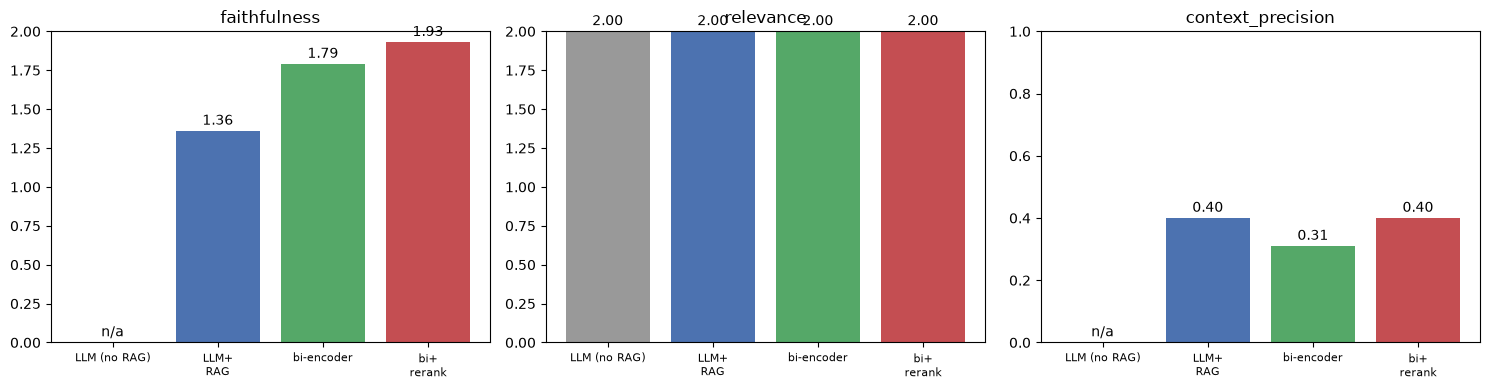

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ("faithfulness", "relevance", "context_precision")):
    vals = judge_summary[col]
    ymax = vals.max() + 1.0
    ax.bar(range(len(vals)), vals.fillna(0), color=["#999999", "#4C72B0", "#55A868", "#C44E52"])
    ax.set_xticks(range(len(vals)), [v.replace("RAG ", "").replace(" + ", "+\n") for v in vals.index], fontsize=8)
    ax.set_ylim(0, ymax)
    ax.set_title(col)
    for i, v in enumerate(vals):
        ax.text(i, (0 if pd.isna(v) else v) + ymax * 0.02, "n/a" if pd.isna(v) else f"{v:.2f}", ha="center")
plt.tight_layout()
plt.show()

* context precision@5: 0,31 (bi-encoder) -> 0,40 (rerank), LLM + RAG ma ten sam kontekst co rerank
* faithfulness: 1,79 (bi-encoder), 1,93 (rerank), 1,43 (LLM + RAG)
   * pozwolenie na własną wiedzę wyraźnie obniża zgodność z kontekstem
   * ścisły RAG prawie zawsze trzyma się kontekstu - błędy biorą się ze złego kontekstu, a nie z ignorowania go

In [35]:
# Per typ pytania
results.pivot_table(index="type", columns="variant", values="relevance", aggfunc="mean").round(2)[VARIANTS]

variant,LLM (no RAG),LLM + RAG,RAG bi-encoder,RAG bi + rerank
type,,,,
"PL, bez wspólnych słów",2.0,2.0,2.0,2.0
"PL, wspólne słowo",2.0,2.0,2.0,2.0
fakt w korpusie,2.0,2.0,2.0,2.0
fałszywe założenie,2.0,2.0,2.0,2.0
negacja,2.0,2.0,2.0,2.0
opinia,2.0,2.0,2.0,2.0
poza korpusem,2.0,2.0,2.0,2.0


* relevance wychodzi 2,0 wszędzie, też dla odpowiedzi bez RAG ze zmyśloną recenzją
   * sędzia nie ma ground truth i ocenia tylko, czy odpowiedź jest na temat, a nie czy jest prawdziwa
   * ta metryka nic tu nie rozróżnia

In [ ]:
def show_context(query: str, variant: str = "RAG bi + rerank") -> None:
    docs = results[(results["query"] == query) & (results["variant"] == variant)]["docs"].iloc[0]
    for i, d in enumerate(docs, start=1):
        m = d.metadata
        ce = f", ce={m['ce_score']:.2f}" if m["ce_score"] is not None else ""
        print(f"[{i}] review {m['review_id']}/{m['chunk_id']}, {m['label']}, bi_rank={m['bi_rank']}{ce}")
        print(f"{d.page_content[:400]}...\n")

show_context("What do reviewers criticize about the endings of horror movies?")

[1] review 843/0, negative, bi_rank=1, ce=2.49
When it comes to horror movies, I am more than willing to suspend disbelief, ignore sub-par production values, and overlook plot holes in the interest of a good scare. This movies simply has no good scares to offer. It can't even be enjoyed as camp. Bad dialogue, bad acting, bad direction, the kills were predictable and poorly staged, the music was annoying, the camera work was wretched, even the ...

[2] review 1060/0, negative, bi_rank=16, ce=-0.27
I have to say although this movie was formulaic throughout with a plot stolen from films like Friday the 13th/I Know What You Did Last Summer, this movie wasn't that bad. In fact it wasn't as bad as most of the Horror films Hollywood has released recently. The killings although at times a little too imaginative were in most instances just that, original. The cast was mediocre which is to be expect...

[3] review 526/0, positive, bi_rank=17, ce=-2.69
MINOR SPOILER Underrated little Stephen King

* 3 z 5 chunków ma ce < -2, a [4] w ogóle nie dotyczy zakończenia
* przy stałym top 5 reranker dopycha słabe fragmenty - można by dodać próg na score cross-encodera

In [37]:
show_context("Which movies are recommended for children and why?")

[1] review 4244/0, positive, bi_rank=10, ce=1.83
I am a big fan a Faerie Tale Theatre and I've seen them all and this is one of the best! It's funny, romantic, and a classic. I recommend this for all ages. It's great for little kids because it's well, Cinderella and great for adults and teen because it's funny and not over the top. I watched it when I was little and I still watch it now. It has great lines that my family and I quote all the time...

[2] review 909/1, negative, bi_rank=5, ce=1.35
of this movie scenario - so why rub it in their faces? As for an adult audience - you won't find it scary or amusing - just boring, contrived and predictable. And the characters are just wrong - clueless parents, ignorant police, stupid and annoying friends, nasty and manipulative babysitters, and beer drinking/womanizing boyfriends. What great material for kids - does this really sound like a chi...

[3] review 3295/0, positive, bi_rank=3, ce=-0.25
I'm no fan of newer movies, but this one was 

* [2] i [4] to dwa chunki tej samej recenzji, a w odpowiedzi robi się z tego "some reviewers"

In [38]:
show_context("Jakie filmy o wojnie recenzenci uważają za wiarygodne i bliskie prawdy?", "RAG bi-encoder")

[1] review 2967/1, positive, bi_rank=1
movie is in Scottish Gaelic with English Subtitles, but do not let that detract you if you are not a speaker of the Gaelic: I am just starting, and my son does not, nor did many people there tonight, and it did not spoil it for us by any manner of means! Superlatives do not suffice! The photography is superb - there is no CGI here, and the movie is all the better for that- here you have true photo...

[2] review 3110/0, positive, bi_rank=2
Along with the "Maratonci trce pocasni krug" from the same director, one of the masterpieces of ex-Yugoslavia comedies. If you want to understand Serbian mentality, you must see this movie. And if you want to see several of ex-Yugoslav great actors at the same time, this is a opportunity....

[3] review 58/0, positive, bi_rank=3
My abiding love of Italian actress Lucianna Paluzzi, who helped jump-start my puberty with her performance in 1965's "Thunderball," has led me to some fairly unusual places. Case in poin

* w top 5 nie ma nic o wojnie (film po gaelicku, jugosłowiańska komedia, Thunderball) - angielski bi-encoder nie radzi sobie z polskim pytaniem bez wspólnych słów

## 7. Wnioski

* RAG daje odpowiedzi oparte na recenzjach, ze źródłami
   * model potrafi odmówić, kiedy w danych nie ma odpowiedzi, zamiast zgadywać
   * bez RAG odpowiada z wiedzy ogólnej i zmyśla szczegóły (recenzje, tytuły, cytaty)
* ścisły prompt (tylko z kontekstu) jest lepszy niż LLM + RAG
   * pozwolenie na własną wiedzę nie uzupełnia luk faktami, tylko dokłada ogólniki i nieoznaczone domysły
   * etykiecie "(general knowledge)" nie da się ufać
   * faithfulness 1,93 -> 1,43
* jakość odpowiedzi zależy głównie od retrievera, a nie od LLM
   * ścisły RAG trzyma się kontekstu, nawet jak kontekst jest zły
   * reranker poprawia trafność kontekstu (precision@5 0,31 -> 0,40) kosztem 2-3 s na zapytanie na CPU
* słabe punkty potoku z cz. I
   * rzadkie nazwy własne
   * pytania w innym języku bez wspólnych słów
   * negacja
   * duplikaty chunków z jednej recenzji
   * możliwe poprawki: BM25 + dense, wielojęzyczny bi-encoder, max 1 chunk na recenzję, próg na score cross-encodera
* ograniczenia
   * korpus bez tytułów filmów i metadanych, recenzje to subiektywne opinie
   * 14 pytań i sędzia LLM bez ground truth - liczby traktuję jako trend, analiza jest głównie jakościowa